In [1]:
from google.colab import files
uploaded = files.upload()

Saving munjal_electronics_dataset.xlsx to munjal_electronics_dataset.xlsx


In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

In [3]:
df = pd.read_excel('munjal_electronics_dataset.xlsx')

In [4]:
df.shape

(1200, 19)

In [5]:
df.head()

,Sale_Date,Brand,Model,RAM,Memory,Category,Price,Price_Range,Quantity_Sold,Quantity_EMI,Quantity_Cash,Revenue,Opening_Stock,Stock_Received,Closing_Stock,Purchase_Cost,Profit,EMI_Provider,Condition
0,2024-11-01,Nothing,CMF Phone 1,6.0,128,Smartphone,5000,10k-20k,1,0,1,5000,1,0.0,0,4500,500,NaN,Old
1,2024-11-01,Oppo,Reno 13,8.0,128,Smartphone,39999,30k-50k,1,0,1,39999,4,0.0,3,38499,1500,NaN,New
2,2024-11-01,Motorola,Edge 50,8.0,256,Smartphone,30999,30k-50k,1,1,0,30999,5,0.0,4,29799,1200,HDB Financial Services:1,New
3,2024-11-01,Oppo,Reno 13,8.0,128,Smartphone,39999,30k-50k,1,1,0,39999,3,0.0,2,38499,1500,HDB Financial Services:1,New
4,2024-11-01,Nothing,CMF Phone 1,6.0,128,Smartphone,16499,10k-20k,1,0,1,16499,1,1.0,1,15799,700,NaN,New


In [7]:
df.columns

Index(['Sale_Date', 'Brand', 'Model', 'RAM', 'Memory', 'Category', 'Price',
       'Price_Range', 'Quantity_Sold', 'Quantity_EMI', 'Quantity_Cash',
       'Revenue', 'Opening_Stock', 'Stock_Received', 'Closing_Stock',
       'Purchase_Cost', 'Profit', 'EMI_Provider', 'Condition'],
      dtype='object')

In [10]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
RAM,1200.0,6.663333,3.527798,0.5,4.00,8.0,8.00,12.0
Memory,1200.0,150.937500,92.148791,1.0,128.00,128.0,256.00,256.0
Price,1200.0,26715.918333,26475.034308,1000.0,9424.25,17650.0,39999.00,127999.0
Quantity_Sold,1200.0,1.715833,1.604856,1.0,1.00,1.0,1.00,8.0
Quantity_EMI,1200.0,0.241667,0.452881,0.0,0.00,0.0,0.00,2.0
Quantity_Cash,1200.0,1.474167,1.740744,0.0,1.00,1.0,1.00,8.0
Revenue,1200.0,30212.780000,26833.694286,2000.0,12999.00,18999.0,40618.75,155998.0
Opening_Stock,1200.0,3.722500,2.953432,-2.0,1.00,3.0,6.00,10.0
Stock_Received,1199.0,0.387823,0.876641,0.0,0.00,0.0,0.00,6.0
Closing_Stock,1200.0,2.393333,2.342690,-3.0,0.00,2.0,4.00,9.0


In [ ]:
df.head()

,Sale_Date,Brand,Model,RAM,Memory,Category,Price,Price_Range,Quantity_Sold,Quantity_EMI,Quantity_Cash,Revenue,Opening_Stock,Stock_Received,Closing_Stock,Purchase_Cost,Profit,EMI_Provider,Condition
0,2024-11-01,Nothing,CMF Phone 1,6.0,128,Smartphone,5000,10k-20k,1,0,1,5000,1,0.0,0,4500,500,NaN,Old
1,2024-11-01,Oppo,Reno 13,8.0,128,Smartphone,39999,30k-50k,1,0,1,39999,4,0.0,3,38499,1500,NaN,New
2,2024-11-01,Motorola,Edge 50,8.0,256,Smartphone,30999,30k-50k,1,1,0,30999,5,0.0,4,29799,1200,HDB Financial Services:1,New
3,2024-11-01,Oppo,Reno 13,8.0,128,Smartphone,39999,30k-50k,1,1,0,39999,3,0.0,2,38499,1500,HDB Financial Services:1,New
4,2024-11-01,Nothing,CMF Phone 1,6.0,128,Smartphone,16499,10k-20k,1,0,1,16499,1,1.0,1,15799,700,NaN,New


In [ ]:
df['Stock_Turnover'] = df['Quantity_Sold'] / df['Opening_Stock']

In [ ]:
df['Sale_Date'] = pd.to_datetime(df['Sale_Date'])
df['Year_Month'] = df['Sale_Date'].dt.to_period('M')

_______________________________________
_______________________________________
# **1. Sales Performance Analysis**
_______________________________________
_______________________________________

In [ ]:
monthly_sales = (
    df.groupby('Year_Month', as_index=False)
      .agg({
          'Quantity_Sold': 'sum',
          'Revenue': 'sum'
      })
)

monthly_sales

,Year_Month,Quantity_Sold,Revenue
0,2024-11,344,6337312
1,2024-12,291,6459269
2,2025-01,366,5814152
3,2025-02,352,6160726
4,2025-03,346,6030053
5,2025-04,360,5453824


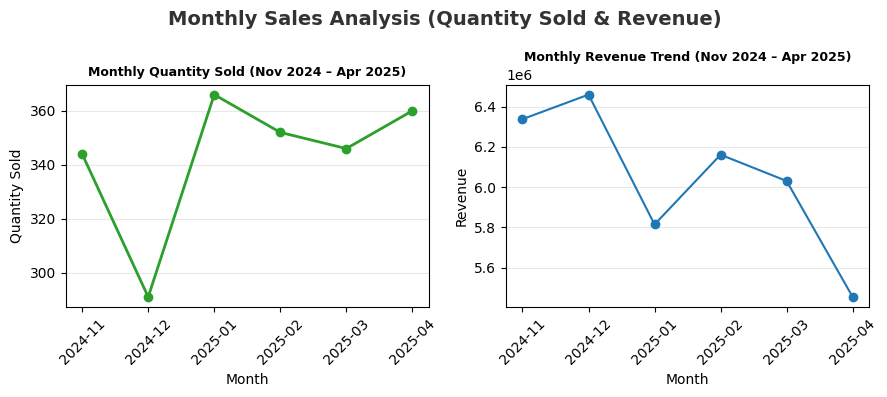

In [ ]:


fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9, 4))

ax1.plot(
    monthly_sales['Year_Month'].astype(str),
    monthly_sales['Quantity_Sold'],
    marker='o',
    color='#2ca02c',
    linewidth=2
)
ax1.set_xlabel('Month')
ax1.set_ylabel('Quantity Sold')
ax1.set_title('Monthly Quantity Sold (Nov 2024 – Apr 2025)', fontsize=9, fontweight='bold')
ax1.tick_params(axis='x', rotation=45)
ax1.grid(axis='y', color='#d9d9d9', alpha=0.6)


ax2.plot(monthly_sales['Year_Month'].astype(str),
         monthly_sales['Revenue'],
         marker='o')

ax2.set_xlabel('Month')
ax2.set_ylabel('Revenue')
ax2.set_title('Monthly Revenue Trend (Nov 2024 – Apr 2025)',fontsize=9, fontweight='bold')
ax2.tick_params(axis='x', rotation=45)
ax2.grid(axis='y', color='#d9d9d9', alpha=0.6)
plt.suptitle(
    'Monthly Sales Analysis (Quantity Sold & Revenue)',
    fontsize=14,
    fontweight='bold',
    color='#333333'
    )

plt.tight_layout()
plt.show()

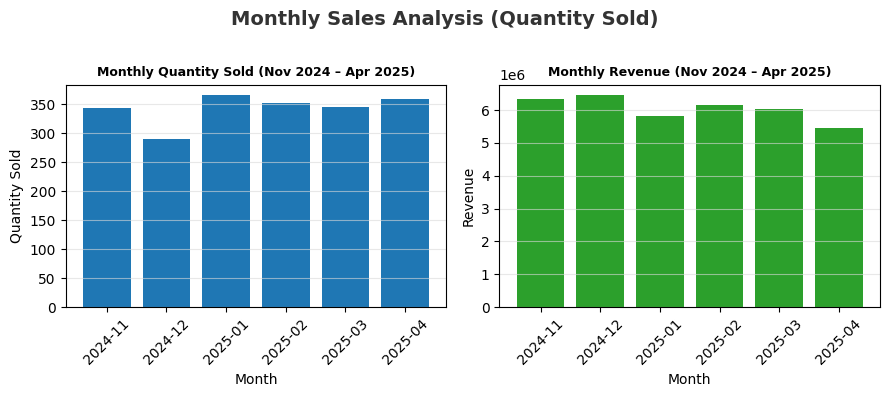

In [ ]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9, 4))

# Bar plot
ax1.bar(
    monthly_sales['Year_Month'].astype(str),
    monthly_sales['Quantity_Sold'],
    color='#1f77b4'
)
ax1.set_xlabel('Month')
ax1.set_ylabel('Quantity Sold')
ax1.set_title('Monthly Quantity Sold (Nov 2024 – Apr 2025)', fontsize=9, fontweight='bold')
ax1.tick_params(axis='x', rotation=45)
ax1.grid(axis='y', color='#d9d9d9', alpha=0.6)


#Bar Plot
ax2.bar(monthly_sales['Year_Month'].astype(str),
        monthly_sales['Revenue'],
        color='#2ca02c')
ax2.set_xlabel('Month')
ax2.set_ylabel('Revenue')
ax2.set_title('Monthly Revenue (Nov 2024 – Apr 2025)',fontsize=9, fontweight='bold')
ax2.tick_params(axis='x', rotation=45)
ax2.grid(axis='y', color='#d9d9d9', alpha=0.6)

plt.suptitle(
    'Monthly Sales Analysis (Quantity Sold)',
    fontsize=14,
    fontweight='bold',
    color='#333333'
)

plt.tight_layout()
plt.show()

---
---
# **2. Price Range & Demand Analysis**
---
---

In [ ]:
price_order = ['<10k', '10k-20k', '20k-30k', '30k-50k', '50k-1L', '>1L']

df['Price_Range'] = pd.Categorical(
    df['Price_Range'],
    categories=price_order,
    ordered=True
)

In [ ]:
price_qty = df.groupby('Price_Range', as_index=False).agg({
    'Quantity_Sold': 'sum'
})

price_rev = df.groupby('Price_Range', as_index=False).agg({
    'Revenue': 'sum'
})

/tmp/ipykernel_832/3021014617.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  price_qty = df.groupby('Price_Range', as_index=False).agg({
/tmp/ipykernel_832/3021014617.py:5: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  price_rev = df.groupby('Price_Range', as_index=False).agg({


## Price Sensitivity Analysis

In [ ]:
price_analysis = df.groupby('Price_Range').agg({
    'Quantity_Sold': 'sum',
    'Revenue': 'sum'
}).reset_index()

price_analysis['Quantity_Share'] = (
    price_analysis['Quantity_Sold'] / price_analysis['Quantity_Sold'].sum()
) * 100

price_analysis['Revenue_Share'] = (
    price_analysis['Revenue'] / price_analysis['Revenue'].sum()
) * 100

/tmp/ipykernel_832/2309720807.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  price_analysis = df.groupby('Price_Range').agg({


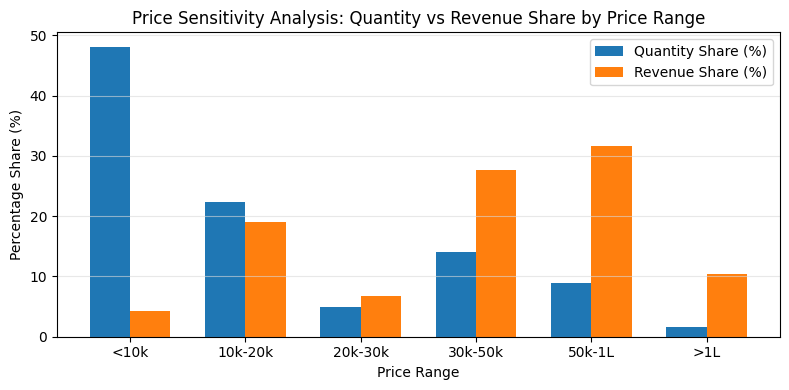

In [ ]:
x = np.arange(len(price_analysis['Price_Range']))
width = 0.35

plt.figure(figsize=(8, 4))

plt.bar(
    x - width/2,
    price_analysis['Quantity_Share'],
    width,
    label='Quantity Share (%)'
)

plt.bar(
    x + width/2,
    price_analysis['Revenue_Share'],
    width,
    label='Revenue Share (%)'
)

# Labels and title
plt.xlabel('Price Range')
plt.ylabel('Percentage Share (%)')
plt.title('Price Sensitivity Analysis: Quantity vs Revenue Share by Price Range')
plt.xticks(x, price_analysis['Price_Range'])
plt.legend()

plt.grid(axis='y', color='#d9d9d9', alpha=0.6)
plt.tight_layout()
plt.show()


/tmp/ipykernel_832/3460688629.py:4: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  monthly_price_qty = pd.pivot_table(
/tmp/ipykernel_832/3460688629.py:18: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  monthly_price_rev = pd.pivot_table(


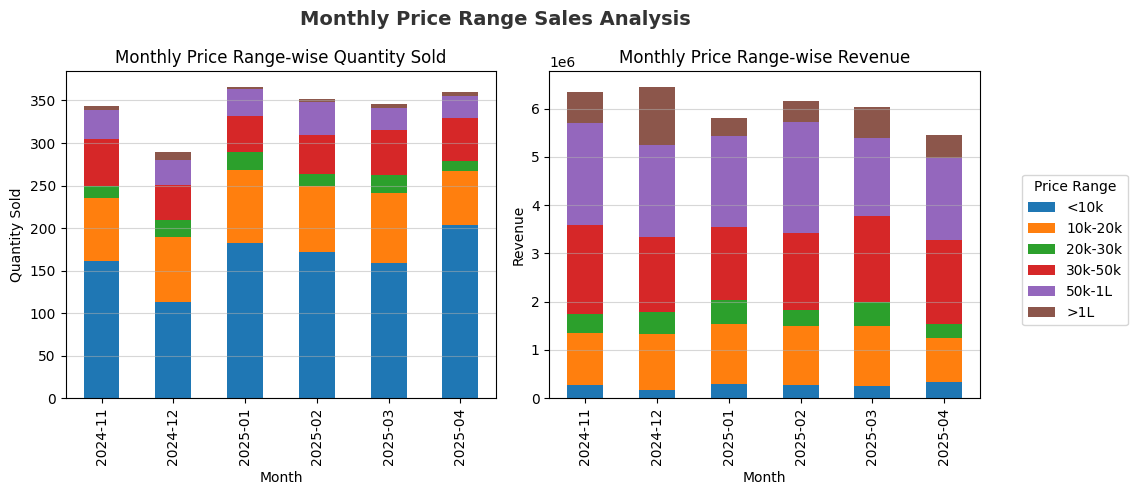

In [ ]:
df['Sale_Date'] = pd.to_datetime(df['Sale_Date'])
df['Year_Month'] = df['Sale_Date'].dt.to_period('M').astype(str)

monthly_price_qty = pd.pivot_table(
    df,
    values='Quantity_Sold',
    index='Year_Month',
    columns='Price_Range',
    aggfunc='sum',
    fill_value=0
)

price_order = ['<10k', '10k-20k', '20k-30k', '30k-50k', '50k-1L', '>1L']
monthly_price_qty = monthly_price_qty[price_order]

#==============================================================================#

monthly_price_rev = pd.pivot_table(
    df,
    values='Revenue',
    index='Year_Month',
    columns='Price_Range',
    aggfunc='sum',
    fill_value=0
)

monthly_price_rev = monthly_price_rev[price_order]

#==============================================================================#

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 5))

# ===================== Quantity Sold ===================== #
monthly_price_qty.plot(
    kind='bar',
    stacked=True,
    ax=ax1
)

ax1.set_xlabel('Month')
ax1.set_ylabel('Quantity Sold')
ax1.set_title('Monthly Price Range-wise Quantity Sold')
ax1.grid(axis='y', alpha=0.5)
ax1.legend_.remove()   # remove duplicate legend

# ===================== Revenue ===================== #
monthly_price_rev.plot(
    kind='bar',
    stacked=True,
    ax=ax2
)

ax2.set_xlabel('Month')
ax2.set_ylabel('Revenue')
ax2.set_title('Monthly Price Range-wise Revenue')
ax2.grid(axis='y', alpha=0.5)
ax2.legend_.remove()
# ===================== Common Legend ===================== #
handles, labels = ax2.get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    title='Price Range',
    bbox_to_anchor=(1.02, 0.5),
    loc='center left'
)

plt.suptitle('Monthly Price Range Sales Analysis', fontsize=14, fontweight='bold', color='#333333')
plt.tight_layout()
plt.show()

----
----
# *3.* **Category-wise Analysis**
----
----

In [ ]:
category_sales = df.groupby('Category', as_index=False).agg({
    'Quantity_Sold': 'sum'
})

category_revenue = df.groupby('Category', as_index=False).agg({
    'Revenue': 'sum'
})

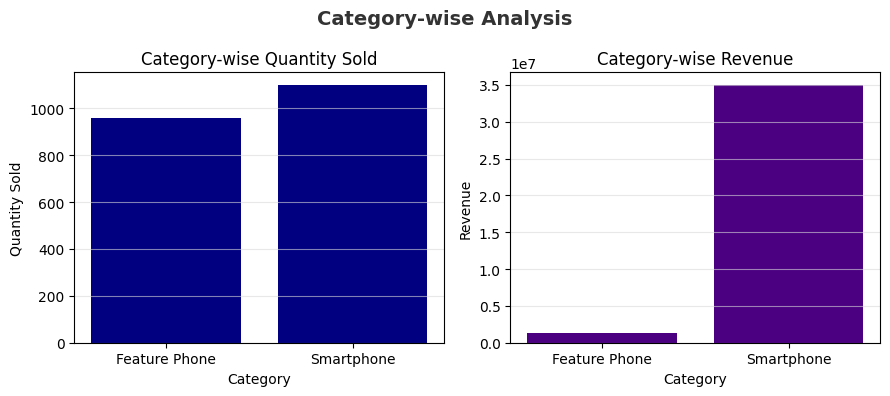

In [ ]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9, 4))

# Category-wise Quantity Sold
ax1.bar(category_sales['Category'], category_sales['Quantity_Sold'], color = 'navy')
ax1.set_xlabel('Category')
ax1.set_ylabel('Quantity Sold')
ax1.set_title('Category-wise Quantity Sold')
ax1.grid(axis='y', color='#d9d9d9', alpha=0.6)

# Category-wise Revenue
ax2.bar(category_revenue['Category'], category_revenue['Revenue'], color='indigo')
ax2.set_xlabel('Category')
ax2.set_ylabel('Revenue')
ax2.set_title('Category-wise Revenue')
ax2.grid(axis='y', color='#d9d9d9', alpha=0.6)

plt.suptitle('Category-wise Analysis', fontsize=14, fontweight='bold', color='#333333')
plt.tight_layout()
plt.show()

-----------
-----------
# **4. Brand-wise and Model-wise Performance**

--------
--------


In [ ]:
brand_sales = (
    df.groupby('Brand', as_index=False)
      .agg({
          'Quantity_Sold': 'sum',
          'Revenue': 'sum'
      })
)

In [ ]:
brand_qty = brand_sales.sort_values(by='Quantity_Sold', ascending=False)
brand_rev = brand_sales.sort_values(by='Revenue', ascending=False)

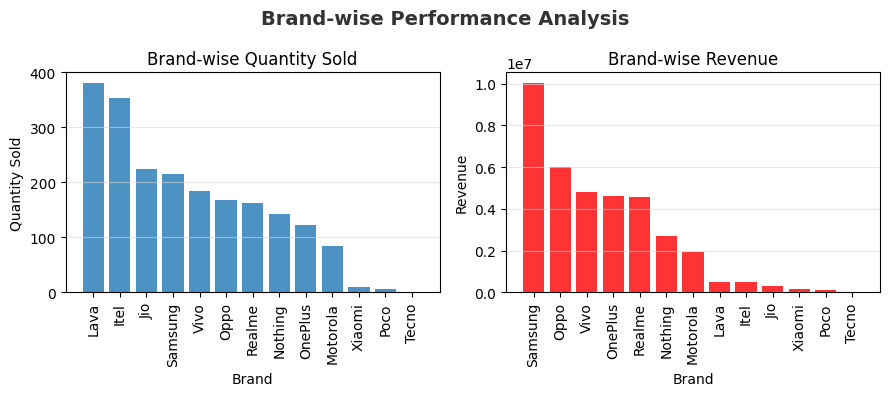

In [ ]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9, 4))

ax1.bar(brand_qty['Brand'], brand_qty['Quantity_Sold'], label='Quantity Sold', alpha=0.8)
ax1.set_xlabel('Brand')
ax1.set_ylabel('Quantity Sold')
ax1.set_title('Brand-wise Quantity Sold')
ax1.grid(axis='y', color='#d9d9d9', alpha=0.6)
ax1.tick_params(axis='x', rotation=90)

ax2.bar(brand_rev['Brand'], brand_rev['Revenue'], label='Revenue', color='red', alpha=0.8)
ax2.set_xlabel('Brand')
ax2.set_ylabel('Revenue')
ax2.set_title('Brand-wise Revenue')
ax2.grid(axis='y', color='#d9d9d9', alpha=0.6)
ax2.tick_params(axis='x', rotation=90)

plt.suptitle('Brand-wise Performance Analysis', fontsize=14, fontweight='bold', color='#333333')
plt.tight_layout()
plt.show()

### Brand-wise analysis (Top 5 Brands)

In [ ]:
df['Sale_Date'] = pd.to_datetime(df['Sale_Date'])
df['Year_Month'] = df['Sale_Date'].dt.to_period('M')
top_brands = (
    df.groupby('Brand')['Revenue']
      .sum()
      .sort_values(ascending=False)
      .head(5)
      .index
)

top_brands

Index(['Samsung', 'Oppo', 'Vivo', 'OnePlus', 'Realme'], dtype='object', name='Brand')

In [ ]:
monthly_brand_revenue = (
    df[df['Brand'].isin(top_brands)]
    .groupby(['Year_Month', 'Brand'], as_index=False)
    .agg({'Revenue': 'sum'})
)

### Monthly Brand-wise Revenue Comparison (Top 5 Brands)

In [ ]:
pivot_df = monthly_brand_revenue.pivot(
    index='Year_Month',
    columns='Brand',
    values='Revenue'
)

pivot_df = pivot_df[top_brands]

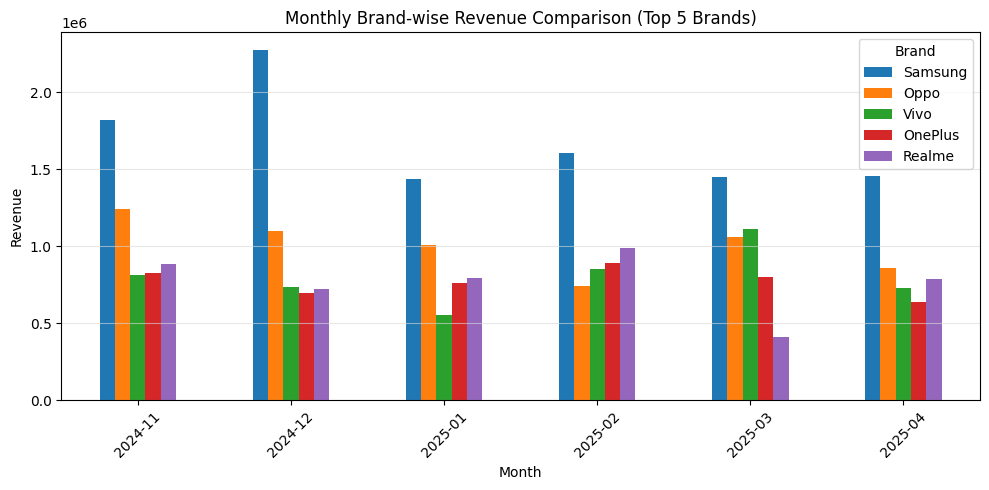

In [ ]:
pivot_df.plot(
    kind='bar',
    figsize=(10,5)
)

plt.xlabel('Month')
plt.ylabel('Revenue')
plt.title('Monthly Brand-wise Revenue Comparison (Top 5 Brands)')
plt.xticks(rotation=45)
plt.legend(title='Brand')
plt.tight_layout()
plt.grid(axis='y', color='#d9d9d9', alpha=0.6)
plt.show()

----
----
# 5. **Inventory Efficiency & Optimization Analysis**
----
----

## Stock vs Sales Analysis

In [ ]:
df_inv = df[
    (df['Category'] == 'Smartphone') &
    (df['Condition'] == 'New')
].copy()

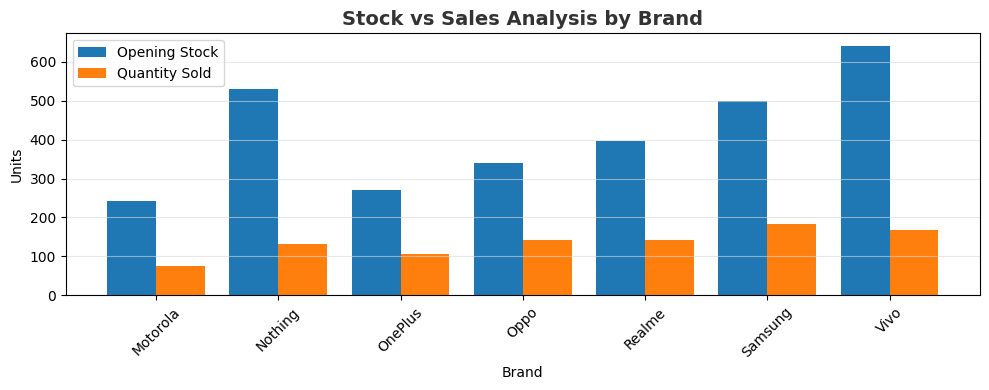

In [ ]:
stock_sales = df_inv.groupby('Brand').agg({
    'Opening_Stock': 'sum',
    'Quantity_Sold': 'sum'
}).reset_index()

x = np.arange(len(stock_sales['Brand']))
width = 0.4

plt.figure(figsize=(10, 4))

plt.bar(x - width/2, stock_sales['Opening_Stock'], width, label='Opening Stock')
plt.bar(x + width/2, stock_sales['Quantity_Sold'], width, label='Quantity Sold')

plt.xticks(x, stock_sales['Brand'], rotation=45)
plt.xlabel('Brand')
plt.ylabel('Units')
plt.title('Stock vs Sales Analysis by Brand', fontsize=14, fontweight='bold', color='#333333')
plt.legend()

plt.grid(axis='y', color='#d9d9d9', alpha=0.6)
plt.tight_layout()
plt.show()

## Stock Turnover Analysis

### Stock Turnover by Brand

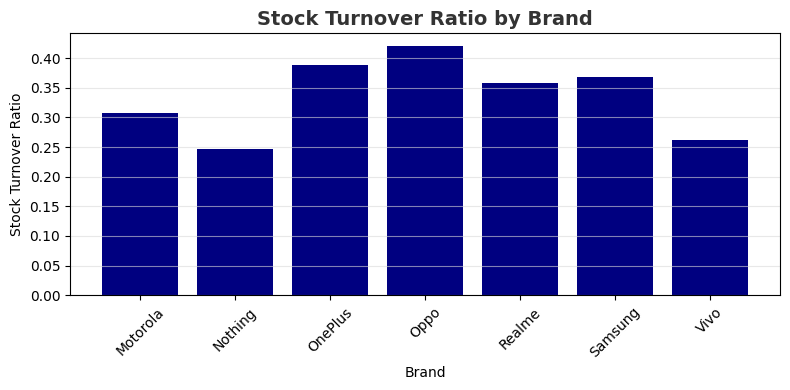

In [ ]:
stock_sales['Stock_Turnover'] = (
    stock_sales['Quantity_Sold'] / stock_sales['Opening_Stock']
)

plt.figure(figsize=(8,4))
plt.bar(stock_sales['Brand'], stock_sales['Stock_Turnover'], color='navy')
plt.xticks(rotation=45)
plt.xlabel('Brand')
plt.ylabel('Stock Turnover Ratio')
plt.title('Stock Turnover Ratio by Brand', fontsize=14, fontweight='bold', color='#333333')

plt.grid(axis='y', color='#d9d9d9', alpha=0.6)
plt.tight_layout()
plt.show()

### Stock Turnover by Price Range

/tmp/ipykernel_832/1637087519.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  price_turnover = df_inv.groupby('Price_Range').agg({


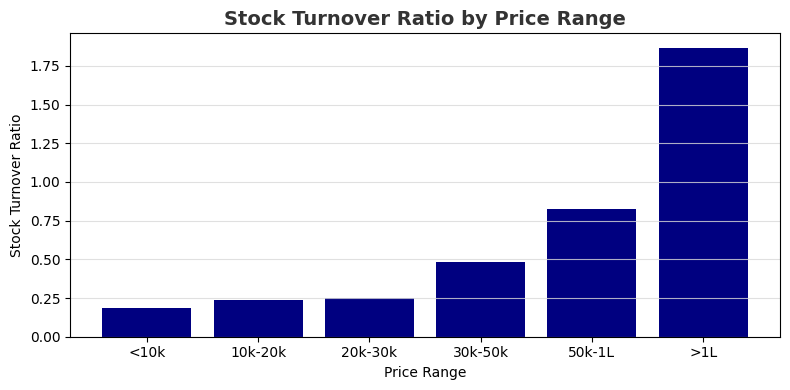

In [ ]:
price_turnover = df_inv.groupby('Price_Range').agg({
    'Opening_Stock': 'sum',
    'Quantity_Sold': 'sum'
}).reset_index()

price_turnover['Stock_Turnover'] = (
    price_turnover['Quantity_Sold'] / price_turnover['Opening_Stock']
)

plt.figure(figsize=(8,4))
plt.bar(price_turnover['Price_Range'], price_turnover['Stock_Turnover'], color='navy')
plt.xlabel('Price Range')
plt.ylabel('Stock Turnover Ratio')
plt.title('Stock Turnover Ratio by Price Range', fontsize=14, fontweight='bold', color='#333333')

plt.grid(axis='y', color='#d9d9d9', alpha=0.8)
plt.tight_layout()
plt.show()

## Brand × Price Range Dominance Analysis

/tmp/ipykernel_832/199102276.py:1: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  brand_price_qty = pd.pivot_table(


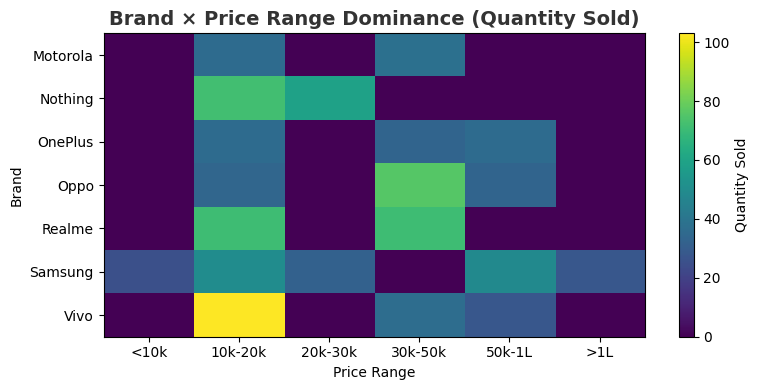

In [ ]:
brand_price_qty = pd.pivot_table(
    df_inv,
    values='Quantity_Sold',
    index='Brand',
    columns='Price_Range',
    aggfunc='sum',
    fill_value=0
)

plt.figure(figsize=(8,4))
plt.imshow(brand_price_qty, aspect='auto')

plt.colorbar(label='Quantity Sold')
plt.xticks(range(len(brand_price_qty.columns)), brand_price_qty.columns)
plt.yticks(range(len(brand_price_qty.index)), brand_price_qty.index)

plt.title('Brand × Price Range Dominance (Quantity Sold)', fontsize=14, fontweight='bold', color='#333333')
plt.xlabel('Price Range')
plt.ylabel('Brand')


plt.tight_layout()
plt.show()

# **EMI VS Cash Analysis**

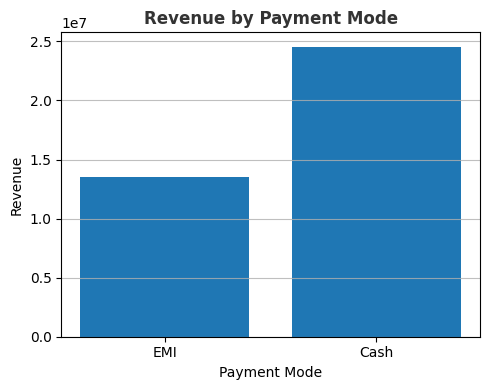

In [ ]:
payment_revenue = {
    'EMI': df.loc[df['Quantity_EMI'] > 0, 'Revenue'].sum(),
    'Cash': df.loc[df['Quantity_Cash'] > 0, 'Revenue'].sum()
}

payment_revenue_df = pd.DataFrame(
    list(payment_revenue.items()),
    columns=['Payment Mode', 'Revenue']
)

plt.figure(figsize=(5,4))
plt.bar(
    payment_revenue_df['Payment Mode'],
    payment_revenue_df['Revenue']
)

plt.title('Revenue by Payment Mode', fontweight='bold', color='#333333')
plt.xlabel('Payment Mode')
plt.ylabel('Revenue')
plt.grid(axis='y', alpha=0.8)

plt.tight_layout()
plt.show()


## Brand-wise EMI Usage

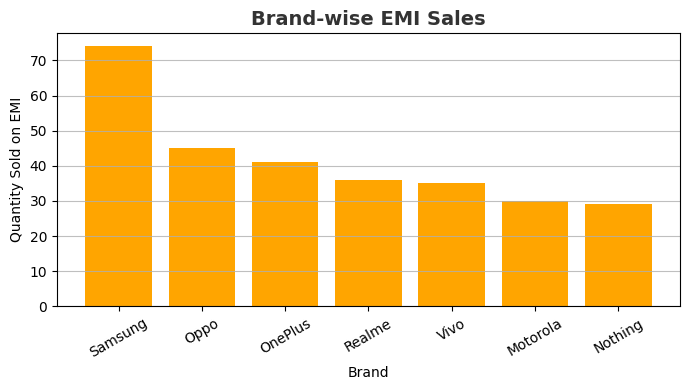

In [ ]:
brand_emi = (
    df_pay.groupby('Brand')['Quantity_EMI']
    .sum()
    .reset_index()
    .sort_values(by='Quantity_EMI', ascending=False)
)

plt.figure(figsize=(7,4))
plt.bar(brand_emi['Brand'], brand_emi['Quantity_EMI'], color='orange')
plt.xlabel('Brand')
plt.ylabel('Quantity Sold on EMI')
plt.title('Brand-wise EMI Sales', fontsize=14, fontweight='bold', color='#333333')
plt.xticks(rotation=30)

plt.tight_layout()
plt.grid(axis='y', alpha=0.8)
plt.show()

## Monthly EMI Trend – Provider-wise

In [ ]:
df_pay['EMI_Provider_Clean'] = (
    df_pay['EMI_Provider']
    .str.extract('(Bajaj Finserv|HDB Financial Services|IDBI Bank)', expand=False)
)

## EMI Provider × Price Range Analysis

/tmp/ipykernel_832/2974322211.py:1: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  provider_price = pd.pivot_table(


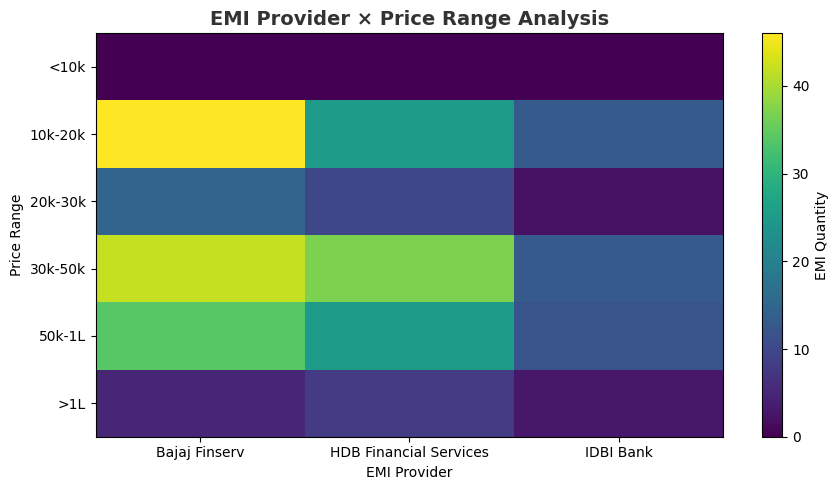

In [ ]:
provider_price = pd.pivot_table(
    df_pay,
    values='Quantity_EMI',
    index='Price_Range',
    columns='EMI_Provider_Clean',
    aggfunc='sum',
    fill_value=0
)

plt.figure(figsize=(9,5))
plt.imshow(provider_price, aspect='auto')

plt.colorbar(label='EMI Quantity')
plt.xticks(range(len(provider_price.columns)), provider_price.columns)
plt.yticks(range(len(provider_price.index)), provider_price.index)

plt.xlabel('EMI Provider')
plt.ylabel('Price Range')
plt.title('EMI Provider × Price Range Analysis', fontsize=14, fontweight='bold', color='#333333')

plt.tight_layout()
plt.show()

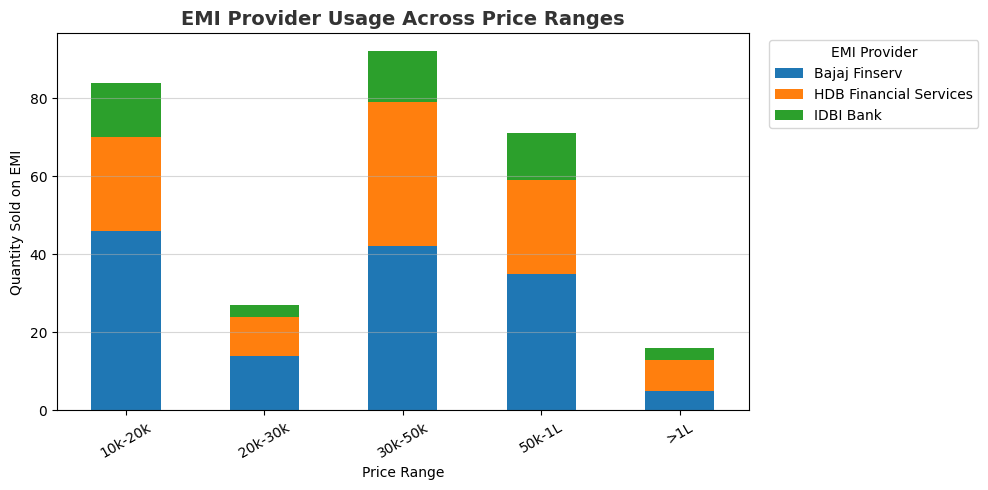

In [ ]:
emi_price_rows = []

for _, row in df[df['Quantity_EMI'] > 0].dropna(subset=['EMI_Provider']).iterrows():
    for item in row['EMI_Provider'].split(','):
        provider, qty = item.strip().split(':')
        emi_price_rows.append({
            'EMI_Provider': provider.strip(),
            'Price_Range': row['Price_Range'],
            'Quantity_EMI': int(qty)
        })

emi_price_df = pd.DataFrame(emi_price_rows)


emi_provider_price = (
    emi_price_df
    .groupby(
        ['Price_Range', 'EMI_Provider'],
        as_index=False,
        observed=True
    )
    .agg({'Quantity_EMI': 'sum'})
)

price_order = ['<10k', '10k-20k', '20k-30k', '30k-50k', '50k-1L', '>1L']

emi_provider_price['Price_Range'] = pd.Categorical(
    emi_provider_price['Price_Range'],
    categories=price_order,
    ordered=True
)

emi_provider_price = emi_provider_price.sort_values('Price_Range')

pivot_provider_price = emi_provider_price.pivot(
    index='Price_Range',
    columns='EMI_Provider',
    values='Quantity_EMI'
).fillna(0)

pivot_provider_price.plot(
    kind='bar',
    stacked=True,
    figsize=(10,5)
)

plt.xlabel('Price Range')
plt.ylabel('Quantity Sold on EMI')
plt.title('EMI Provider Usage Across Price Ranges', fontsize=14, fontweight='bold', color='#333333')
plt.xticks(rotation=30)
plt.legend(title='EMI Provider', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.grid(axis='y', alpha=0.5)
plt.show()

## EMI Provider-wise Quantity Financed

In [ ]:
emi_df = df[df['Quantity_EMI'] > 0][['EMI_Provider']].dropna()

emi_rows = []

for providers in emi_df['EMI_Provider']:
    for item in providers.split(','):
        name, qty = item.strip().split(':')
        emi_rows.append({
            'EMI_Provider': name.strip(),
            'Quantity_EMI': int(qty)
        })

emi_provider_df = pd.DataFrame(emi_rows)

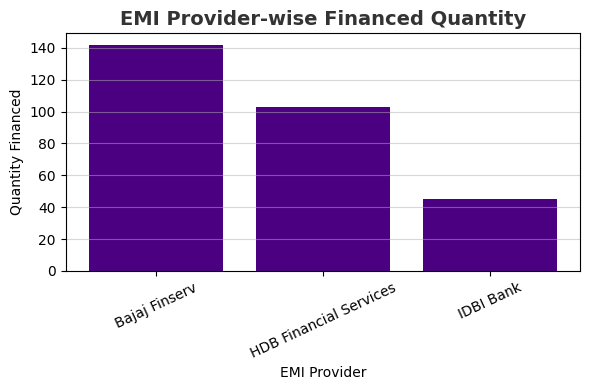

In [ ]:
emi_summary = (
    emi_provider_df
    .groupby('EMI_Provider', as_index=False)
    .agg({'Quantity_EMI': 'sum'})
    .sort_values(by='Quantity_EMI', ascending=False)
)

plt.figure(figsize=(6,4))
plt.bar(emi_summary['EMI_Provider'], emi_summary['Quantity_EMI'], color='indigo')
plt.xlabel('EMI Provider')
plt.ylabel('Quantity Financed')
plt.title('EMI Provider-wise Financed Quantity', fontsize=14, fontweight='bold', color='#333333')
plt.xticks(rotation=25)
plt.tight_layout()
plt.grid(axis='y', alpha=0.5)
plt.show()

# **ABC Analysis**

In [ ]:
df_abc = df[df['Condition'] == 'New'].copy()

In [ ]:
df_abc['SKU'] = (
    df_abc['Brand'].astype(str) + ' | ' +
    df_abc['Model'].astype(str) + ' | ' +
    df_abc['RAM'].astype(str) + 'GB RAM | ' +
    df_abc['Memory'].astype(str) + 'GB | New'
)

In [ ]:
sku_revenue = (
    df.groupby('Model', as_index=False)
      .agg({'Revenue': 'sum'})
)

In [ ]:
sku_revenue = sku_revenue.sort_values(by='Revenue', ascending=False)


In [ ]:
sku_revenue['Revenue_Share'] = (
    sku_revenue['Revenue'] / sku_revenue['Revenue'].sum()
)

sku_revenue['Cumulative_Revenue'] = sku_revenue['Revenue_Share'].cumsum()


In [ ]:
def abc_classification(cum):
    if cum <= 0.70:
        return 'A'
    elif cum <= 0.90:
        return 'B'
    else:
        return 'C'

sku_revenue['ABC_Category'] = sku_revenue['Cumulative_Revenue'].apply(abc_classification)

In [ ]:
sku_revenue[['Model', 'Revenue', 'ABC_Category']].head()

,Model,Revenue,ABC_Category
82,S24 Ultra,3669762,A
50,GT6,3067370,A
7,13,2452122,A
43,Find X8,2423473,A
83,S25,2082863,A


## Graph 1: ABC Category Distribution (Pie Chart)
### Revenue contribution by ABC category

In [ ]:
abc_revenue_dist = (
    sku_revenue
    .groupby('ABC_Category')['Revenue']
    .sum()
    .reindex(['A', 'B', 'C'])
)

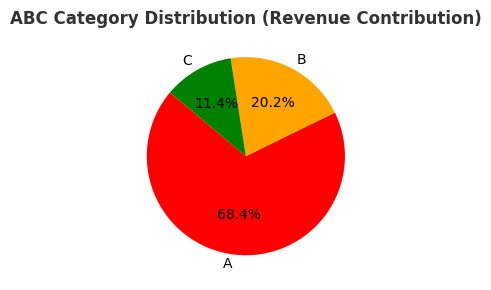

In [ ]:
plt.figure(figsize=(3,3))
plt.pie(
    abc_revenue_dist,
    labels=abc_revenue_dist.index,
    autopct='%1.1f%%',
    startangle=140,
    colors=['red', 'orange', 'green']
)
plt.title('ABC Category Distribution (Revenue Contribution)', fontweight='bold', color='#333333')
plt.tight_layout()
plt.show()

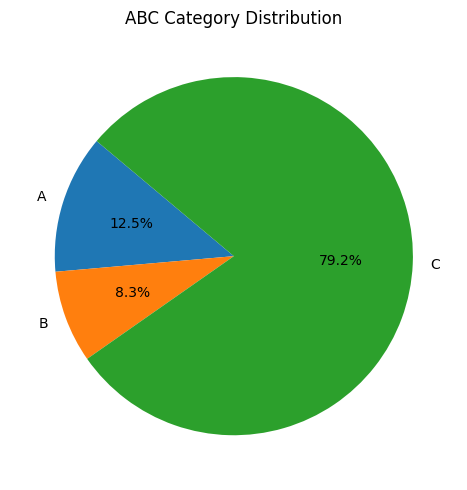

In [ ]:
abc_dist = sku_revenue['ABC_Category'].value_counts().sort_index()

plt.figure(figsize=(5,5))
plt.pie(
    abc_dist.values,
    labels=abc_dist.index,
    autopct='%1.1f%%',
    startangle=140
)
plt.title('ABC Category Distribution')
plt.tight_layout()
plt.show()

In [ ]:
sku_revenue = (
    df[df['Condition'] == 'New']
    .groupby(['Brand', 'Model'], as_index=False)
    .agg({'Revenue': 'sum'})
)

In [ ]:
sku_revenue = sku_revenue.sort_values('Revenue', ascending=False)

In [ ]:

sku_revenue['Cum_Revenue'] = sku_revenue['Revenue'].cumsum()
total_revenue = sku_revenue['Revenue'].sum()
sku_revenue['Cum_Revenue_Pct'] = sku_revenue['Cum_Revenue'] / total_revenue * 100

In [ ]:
def abc_category(pct):
    if pct <= 70:
        return 'A'
    elif pct <= 90:
        return 'B'
    else:
        return 'C'

sku_revenue['ABC_Category'] = sku_revenue['Cum_Revenue_Pct'].apply(abc_category)

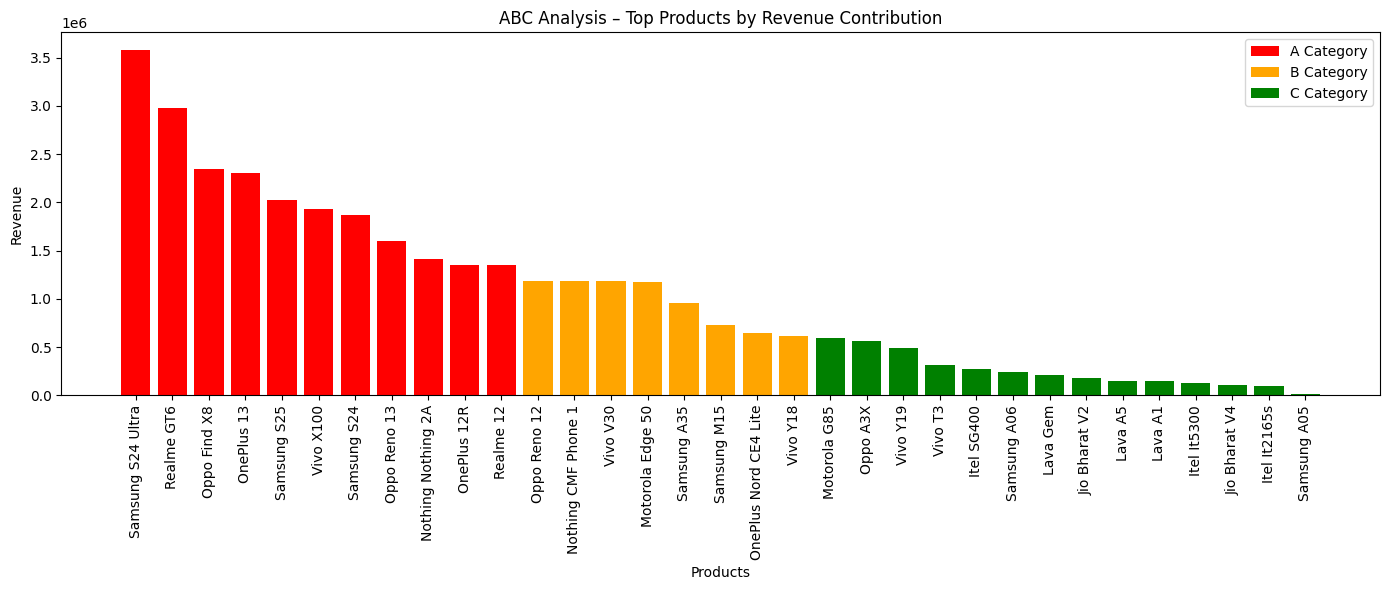

In [ ]:
color_map = {'A': 'red', 'B': 'orange', 'C': 'green'}

plt.figure(figsize=(14,6))
plt.bar(
    sku_revenue['Brand'] + ' ' + sku_revenue['Model'],
    sku_revenue['Revenue'],
    color=sku_revenue['ABC_Category'].map(color_map)
)

plt.xticks(rotation=90)
plt.ylabel('Revenue')
plt.xlabel('Products')
plt.title('ABC Analysis – Top Products by Revenue Contribution')

# Legend
from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor='red', label='A Category'),
    Patch(facecolor='orange', label='B Category'),
    Patch(facecolor='green', label='C Category')
]
plt.legend(handles=legend_elements)

plt.tight_layout()
plt.show()

# **RFM Analysis**

In [ ]:
df['Sale_Date'] = pd.to_datetime(df['Sale_Date'], errors='coerce')
df = df.dropna(subset=['Sale_Date'])

reference_date = df['Sale_Date'].max()

In [ ]:
rfm = df.groupby('Model').agg({
    'Sale_Date': lambda x: (reference_date - x.max()).days,
    'Quantity_Sold': 'sum',
    'Profit': 'sum'
}).reset_index()

rfm.columns = ['Model', 'Recency', 'Frequency', 'Monetary']


In [ ]:
rfm['R_rank'] = rfm['Recency'].rank(method='first', ascending=True)
rfm['F_rank'] = rfm['Frequency'].rank(method='first', ascending=False)
rfm['M_rank'] = rfm['Monetary'].rank(method='first', ascending=False)

In [ ]:
rfm['R_Score'] = pd.qcut(rfm['R_rank'], 5, labels=[5,4,3,2,1])
rfm['F_Score'] = pd.qcut(rfm['F_rank'], 5, labels=[1,2,3,4,5])
rfm['M_Score'] = pd.qcut(rfm['M_rank'], 5, labels=[1,2,3,4,5])

In [ ]:
rfm['RFM_Total'] = (
    rfm['R_Score'].astype(int) +
    rfm['F_Score'].astype(int) +
    rfm['M_Score'].astype(int)
)

In [ ]:
def segment(x):
    if x >= 13:
        return 'Star Product'
    elif x >= 10:
        return 'Good Performer'
    elif x >= 7:
        return 'Average'
    else:
        return 'Slow Mover'

rfm['Segment'] = rfm['RFM_Total'].apply(segment)

In [ ]:
abc = df.groupby('Model')['Revenue'].sum().reset_index()
abc = abc.sort_values(by='Revenue', ascending=False)

abc['Revenue_%'] = abc['Revenue'] / abc['Revenue'].sum()
abc['Cumulative_%'] = abc['Revenue_%'].cumsum()

def abc_category(x):
    if x <= 0.80:
        return 'A'
    elif x <= 0.95:
        return 'B'
    else:
        return 'C'

abc['ABC_Category'] = abc['Cumulative_%'].apply(abc_category)


In [ ]:
rfm_abc = rfm.merge(abc[['Model', 'ABC_Category']], on='Model')

In [ ]:
def strategy(row):
    if row['ABC_Category'] == 'A' and row['Segment'] == 'Star Product':
        return 'Core Focus Product'
    elif row['ABC_Category'] == 'A':
        return 'Revenue Critical – Improve Movement'
    elif row['Segment'] == 'Star Product':
        return 'Emerging High Potential'
    elif row['Segment'] == 'Slow Mover':
        return 'Reduce Stock / Discount'
    else:
        return 'Maintain Strategy'

rfm_abc['Strategy'] = rfm_abc.apply(strategy, axis=1)

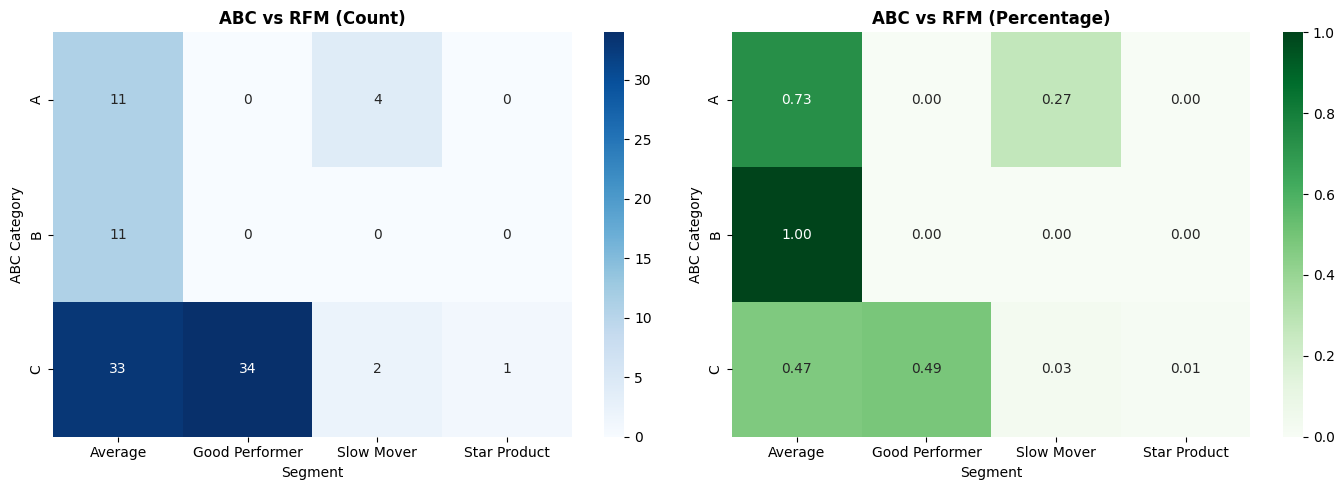

In [ ]:
pivot_count = pd.crosstab(rfm_abc['ABC_Category'], rfm_abc['Segment'])
pivot_pct = pivot_count.div(pivot_count.sum(axis=1), axis=0)

fig, axes = plt.subplots(1, 2, figsize=(14,5))

sns.heatmap(
pivot_count,
annot=True,
cmap='Blues',
fmt='d',
ax=axes[0]
)
axes[0].set_title("ABC vs RFM (Count)", fontweight='bold')
axes[0].set_xlabel("Segment")
axes[0].set_ylabel("ABC Category")

sns.heatmap(
pivot_pct,
annot=True,
cmap='Greens',
fmt='.2f',
ax=axes[1]
)
axes[1].set_title("ABC vs RFM (Percentage)", fontweight='bold')
axes[1].set_xlabel("Segment")
axes[1].set_ylabel("ABC Category")

plt.tight_layout()
plt.show()